# BIOT 6900 · Module 8 Assignment — Single-Cell & Spatial Omics
## Starter notebook: one tumor, two views

This is your **starter**. The plumbing is done for you: the two datasets load in one line each, and the tricky steps (whole-donor sampling, scVI setup, Harmony, the spatial graph) are already written. Your job is to fill in the cells marked **`# TODO`** and to answer the **TODO** questions in the markdown.

- **Part 1 (single-cell):** which cell types express your target?
- **Part 2 (spatial):** where do those cells and that target sit in the tumor?
- **Part 3:** connect the two in your report.

How to use it: run top to bottom, completing each TODO as you reach it. The provided cells must run first for the TODO cells to work. When you are done, **Kernel → Restart & Run All** so the whole notebook executes cleanly, then commit it with your report.

> **Compute:** Part 1's scVI step wants a GPU. Run on Explorer via Open OnDemand (JupyterLab on `courses-gpu`, 1 GPU). Part 2 is CPU-only. See the lab guides for the steps.

### Requirements
Environment: the course `biot6900` / Explorer environment (`scanpy`, `cellxgene-census`, `scvi-tools`, `harmonypy`, `squidpy`). Needs **Python 3.13 or earlier**. If an import fails, run the install cell once and restart the kernel.

In [1]:
# Run once only if an import below fails, then restart the kernel. Python <= 3.13.
# !pip install "cellxgene-census" "scvi-tools" harmonypy squidpy scanpy leidenalg igraph

In [2]:
import scanpy as sc
import squidpy as sq
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sc.settings.verbosity = 1
sc.settings.set_figure_params(dpi=80, facecolor="white")
try:
    import torch
    GPU = torch.cuda.is_available()
    print("GPU available:", GPU)
except Exception:
    GPU = False
    print("running on CPU")
print("scanpy", sc.__version__, "| squidpy", sq.__version__)

/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


GPU available: False
scanpy 1.11.5 | squidpy 1.8.2


/var/folders/my/7_8dyc1n26sg4yqmd9z7g8f40000gn/T/ipykernel_22783/1236436484.py:16: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print("scanpy", sc.__version__, "| squidpy", sq.__version__)


---
# PART 1 · Single-cell: which cells express the target

## 1.1 · Pull the breast-cancer data  *(provided)*
This pulls breast-cancer blood/tumor cells from the CZ CELLxGENE Census and samples **10 whole donors**. You do not change anything here.

If the query returns zero cells on your Census version, replace the disease string with the exact one posted on Canvas (Census labels are version-specific).

In [3]:
import cellxgene_census

census = cellxgene_census.open_soma(census_version="stable")
obs = cellxgene_census.get_obs(
    census, "Homo sapiens",
    value_filter="disease == 'breast cancer' and is_primary_data == True",
    column_names=["soma_joinid", "donor_id", "assay", "cell_type"],
)
print(f"matching cells in the Census: {len(obs):,}")

# Sample whole donors (not scattered cells), so batch-aware steps have enough per donor.
rng = np.random.default_rng(0)
cells_per_donor = 2000
donor_sizes = obs["donor_id"].value_counts()
big_donors = donor_sizes[donor_sizes >= cells_per_donor].index.to_numpy()
donors = rng.choice(big_donors, size=min(10, len(big_donors)), replace=False)
sel = np.concatenate([
    rng.choice(obs.loc[obs["donor_id"] == d, "soma_joinid"].to_numpy(), size=cells_per_donor, replace=False)
    for d in donors
])
adata = cellxgene_census.get_anndata(
    census, "Homo sapiens", obs_coords=np.sort(sel),
    obs_column_names=["donor_id", "assay", "cell_type", "disease", "sex"],
    var_column_names=["feature_id", "feature_name"],
)
census.close()
adata.var_names = adata.var["feature_name"].astype(str)
adata.var_names_make_unique()

def broad_type(ct):
    ct = str(ct).lower()
    if "cd4" in ct or "cd8" in ct or "t cell" in ct or "thymocyte" in ct: return "T"
    if "plasma" in ct or "b cell" in ct: return "B"
    if "natural killer" in ct or "innate lymphoid" in ct: return "NK"
    if "monocyte" in ct: return "Monocyte"
    if "dendritic" in ct: return "DC"
    if "macrophage" in ct: return "Macrophage"
    if "epithel" in ct or "luminal" in ct or "basal" in ct or "carcinoma" in ct or "tumor" in ct: return "Epithelial/Tumor"
    if "fibroblast" in ct or "stromal" in ct: return "Fibroblast"
    if "endothel" in ct: return "Endothelial"
    return "Other"
adata.obs["cell_type_broad"] = adata.obs["cell_type"].map(broad_type).astype("category")
print(f"\n{adata.n_obs:,} cells from {len(donors)} donors")
print(adata.obs["cell_type_broad"].value_counts())

The "stable" release is currently 2025-11-08. Specify 'census_version="2025-11-08"' in future calls to open_soma() to ensure data consistency.


matching cells in the Census: 1,101,430


/opt/anaconda3/envs/biot6900/lib/python3.11/functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/opt/anaconda3/envs/biot6900/lib/python3.11/functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)



20,000 cells from 10 donors
cell_type_broad
T                   12121
Other                3125
Endothelial          1466
Macrophage           1260
Fibroblast           1118
B                     586
Epithelial/Tumor      152
Monocyte               73
NK                     61
DC                     38
Name: count, dtype: int64


/var/folders/my/7_8dyc1n26sg4yqmd9z7g8f40000gn/T/ipykernel_22783/3322223012.py:28: UserWarning: Suffix used (-[0-9]+) to deduplicate index values may make index values difficult to interpret. There values with a similar suffixes in the index. Consider using a different delimiter by passing `join={delimiter}`. Example key collisions generated by the make_index_unique algorithm: ['SNORD115-1', 'SNORD115-2', 'SNORD115-3', 'SNORD115-4', 'SNORD115-5']
  adata.var_names_make_unique()


In [4]:
# Assignment Part 1(a) asks for cells, donors AND assays. The provided cell above
# reports cells and donors, so this cell adds the assay breakdown.
# (the Census category list carries every assay that exists, so drop the empty ones)
_assay = adata.obs["assay"].value_counts()
_assay = _assay[_assay > 0]
print(f"cells: {adata.n_obs:,}   donors: {adata.obs['donor_id'].nunique()}   "
      f"assays in use: {len(_assay)}")
print("\ncells by assay:")
print(_assay.to_string())
print("\ndonor x assay:")
_ct = pd.crosstab(adata.obs["donor_id"], adata.obs["assay"])
print(_ct.loc[:, _ct.sum() > 0].to_string())
print("\nNote: pal_Patient 0056 and pal_Patient 0178 are 10x 3' v2, a shallower chemistry")
print("than the 3' v3 / 5' v2 used for the rest, so sequencing depth is confounded with donor.")


cells: 20,000   donors: 10   assays in use: 3

cells by assay:
assay
10x 3' v3    13922
10x 3' v2     4078
10x 5' v2     2000

donor x assay:
assay             10x 3' v2  10x 3' v3  10x 5' v2
donor_id                                         
HTAPP-211                 0       2000          0
HTAPP-313                 0       2000          0
HTAPP-516                 0       2000          0
HTAPP-806                78       1922          0
HTAPP-889                 0       2000          0
HTAPP-997                 0       2000          0
QianBRCA_BC_5             0          0       2000
pal_Patient 0056       2000          0          0
pal_Patient 0176          0       2000          0
pal_Patient 0178       2000          0          0

Note: pal_Patient 0056 and pal_Patient 0178 are 10x 3' v2, a shallower chemistry
than the 3' v3 / 5' v2 used for the rest, so sequencing depth is confounded with donor.


## 1.2 · Standard pipeline  *(provided)*
QC, normalize, batch-aware highly variable genes, PCA. The raw counts are kept for scVI and for marker plots.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
sc.pp.filter_cells(adata, min_genes=200)
adata.layers["counts"] = adata.X.copy()
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)
adata = adata[(adata.obs.n_genes_by_counts < 6000) & (adata.obs.pct_counts_mt < 15)].copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata
# span=0.5 (scanpy default 0.3): the default loess fit is singular on this donor sample. See README.
sc.pp.highly_variable_genes(adata, n_top_genes=2000, flavor="seurat_v3", layer="counts", batch_key="donor_id", span=0.5)
adata = adata[:, adata.var.highly_variable].copy()
sc.pp.scale(adata, max_value=10)
sc.tl.pca(adata, svd_solver="arpack")
print("cells after QC:", adata.n_obs)

/opt/anaconda3/envs/biot6900/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


cells after QC: 18388


## 1.3 · The batch problem
The unintegrated embedding is computed for you. **TODO:** plot it and say what you see.

In [6]:
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=30, use_rep="X_pca")
sc.tl.umap(adata)
adata.obsm["X_umap_unint"] = adata.obsm["X_umap"].copy()

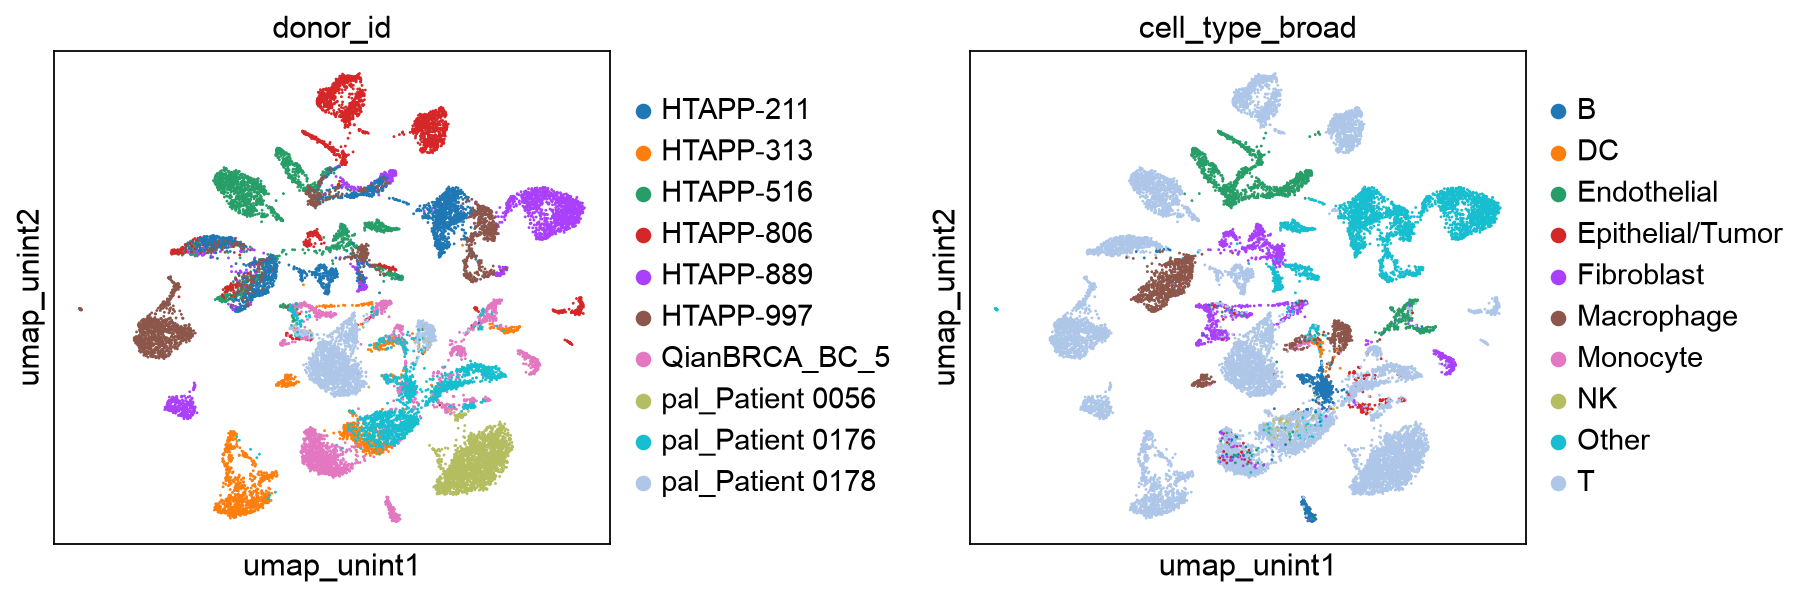

donor silhouette on unintegrated PCA (higher = more donor-separated): 0.095


In [7]:
# TODO: plot the unintegrated UMAP colored by donor and by cell type.
sc.pl.embedding(adata, basis="umap_unint", color=["donor_id", "cell_type_broad"], wspace=0.5)

# how separated are the donors before integration? (same metric used in 1.6)
from sklearn.metrics import silhouette_score
_idx = rng.choice(adata.n_obs, size=min(5000, adata.n_obs), replace=False)
print("donor silhouette on unintegrated PCA (higher = more donor-separated):",
      round(silhouette_score(adata.obsm["X_pca"][_idx], adata.obs["donor_id"].values[_idx]), 3))

**TODO (interpretation):** In one or two sentences, what do these two plots show? Is the data organized by donor or by biology?

**My answer.** The map is organized **by donor, not by biology**: each donor forms its own island, and the same cell type reappears separately inside several of them. The donor silhouette on the unintegrated PCA is **+0.095**: positive, meaning a cell sits closer to other cells from its own donor than to cells of its own type from another donor, which is the batch effect this section is about.

## 1.4 · Integrate with scVI  *(provided, GPU step)*

In [8]:
import scvi
scvi.model.SCVI.setup_anndata(adata, layer="counts", batch_key="donor_id")
vae = scvi.model.SCVI(adata, n_latent=30)
vae.train(max_epochs=(200 if GPU else 60), accelerator=("gpu" if GPU else "cpu"))
adata.obsm["X_scVI"] = vae.get_latent_representation()
sc.pp.neighbors(adata, n_neighbors=15, use_rep="X_scVI")
sc.tl.umap(adata)
adata.obsm["X_umap_scvi"] = adata.obsm["X_umap"].copy()
print("scVI done")

GPU available: True (mps), used: False
TPU available: False, using: 0 TPU cores
/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/lightning/pytorch/trainer/setup.py:175: GPU available but not used. You can set it by doing `Trainer(accelerator='gpu')`.
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoade

Training:   0%|          | 0/60 [00:00<?, ?it/s]

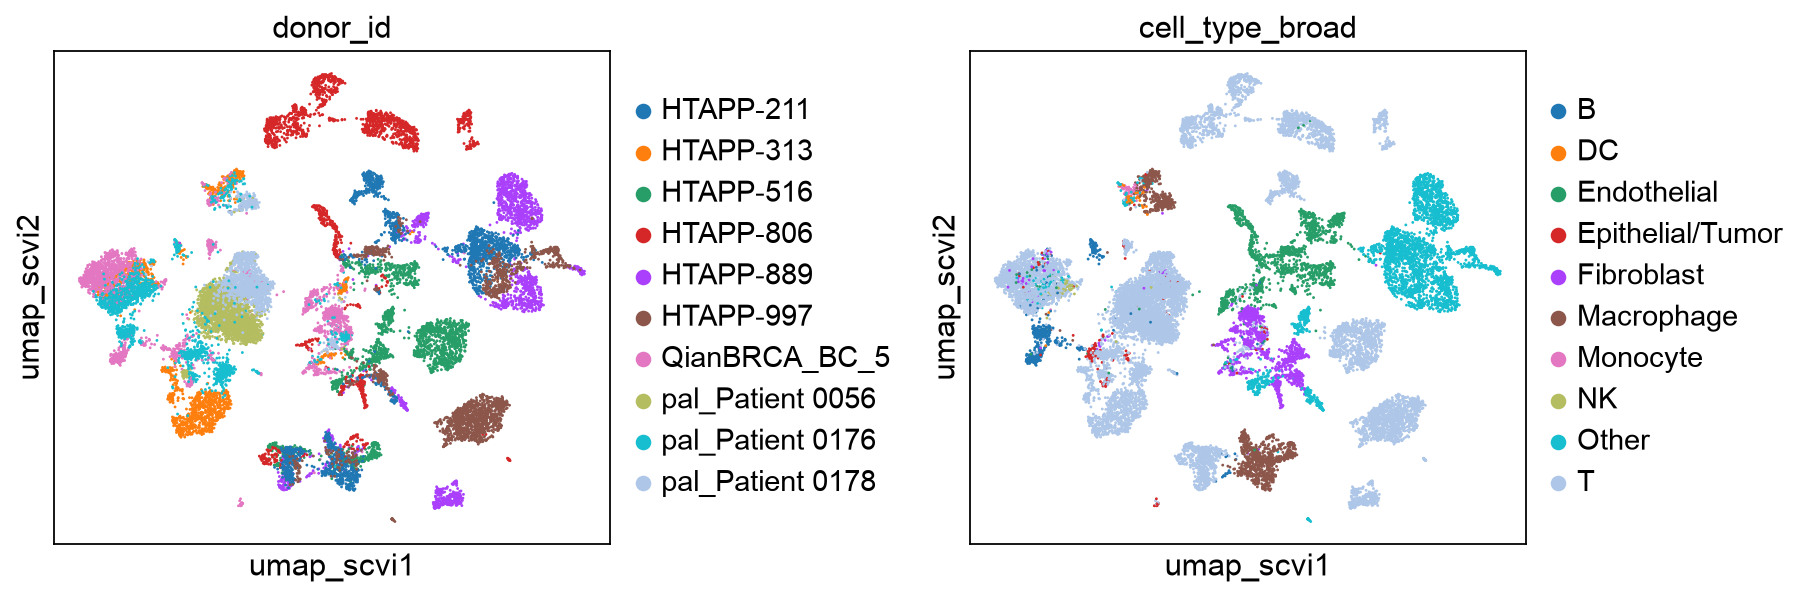

In [9]:
# TODO: plot the scVI UMAP colored by donor and by cell type. Did the donors mix?
sc.pl.embedding(adata, basis="umap_scvi", color=["donor_id", "cell_type_broad"], wspace=0.5)

## 1.5 · Harmony, a fair baseline  *(provided)*

In [10]:
import harmonypy
ho = harmonypy.run_harmony(adata.obsm["X_pca"].astype(np.float64), adata.obs, "donor_id")
Z = np.asarray(ho.Z_corr)
adata.obsm["X_pca_harmony"] = Z if Z.shape[0] == adata.n_obs else Z.T
print("Harmony done")

2026-11-18 23:05:27,461 - harmonypy - INFO - Running Harmony


2026-11-18 23:05:27,461 - harmonypy - INFO -   Parameters:


2026-11-18 23:05:27,461 - harmonypy - INFO -     max_iter_harmony: 10


2026-11-18 23:05:27,462 - harmonypy - INFO -     max_iter_kmeans: 4


2026-11-18 23:05:27,462 - harmonypy - INFO -     epsilon_cluster: 0.001


2026-11-18 23:05:27,462 - harmonypy - INFO -     epsilon_harmony: 0.01


... (19 outputs left out)

2026-11-18 23:05:27,690 - harmonypy - INFO - Iteration 9 of 10


2026-11-18 23:05:27,711 - harmonypy - INFO - Iteration 10 of 10


2026-11-18 23:05:27,733 - harmonypy - INFO - Stopped before convergence


Harmony done


## 1.6 · Judge the fix
**TODO:** compute how well each method (no integration, Harmony, scVI) mixes donors and preserves cell types, then decide which you would use.

In [11]:
from sklearn.metrics import silhouette_score

# TODO: for each embedding, score batch mixing (by donor_id, lower is better)
#       and biology preservation (by cell_type_broad, higher is better).
idx = rng.choice(adata.n_obs, size=min(5000, adata.n_obs), replace=False)
reps = {"No integration": "X_pca", "Harmony": "X_pca_harmony", "scVI": "X_scVI"}

rows = []
for name, key in reps.items():
    emb = np.asarray(adata.obsm[key])[idx]
    batch = silhouette_score(emb, adata.obs["donor_id"].values[idx])        # lower = donors mixed
    bio   = silhouette_score(emb, adata.obs["cell_type_broad"].values[idx]) # higher = biology kept
    rows.append({"method": name, "batch_silhouette (lower better)": round(batch, 3),
                 "bio_silhouette (higher better)": round(bio, 3),
                 "bio - batch": round(bio - batch, 3)})
scores = pd.DataFrame(rows).set_index("method")
print(scores.to_string())
print("\n'bio - batch' is a single summary: high biology separation with low donor separation is what we want.")

                batch_silhouette (lower better)  bio_silhouette (higher better)  bio - batch
method                                                                                      
No integration                            0.089                           0.007       -0.082
Harmony                                  -0.076                           0.043        0.119
scVI                                     -0.032                           0.035        0.068

'bio - batch' is a single summary: high biology separation with low donor separation is what we want.


**TODO (interpretation):** Which method would you use, and why? Does the expensive deep-learning method clearly beat the simple one?

**My answer.** I would use **Harmony**.

| method | batch silhouette (lower better) | bio silhouette (higher better) | bio - batch |
|---|---|---|---|
| No integration | 0.089 | 0.007 | -0.082 |
| **Harmony** | **-0.076** | **0.043** | **0.119** |
| scVI | -0.032 | 0.035 | 0.068 |

Both methods fix the batch problem: the donor silhouette goes from **+0.089** (donors separated) to negative for both, meaning donors are now interleaved. But Harmony wins on *both* axes simultaneously: it mixes donors harder (-0.076 vs -0.032) **and** keeps more cell-type structure (0.043 vs 0.035), giving a combined score of 0.119 against 0.068. There is no trade-off to argue about here; one method dominates.

**So no: the expensive deep-learning method does not clearly beat the simple one. It loses, on both axes, at far higher cost:** Harmony converged in under a second, while scVI took 60 epochs of CPU training.

Three honest caveats. (1) scVI is the method being handicapped here: the notebook trains 200 epochs on a GPU and falls back to 60 on CPU, which is what ran, so it is probably undertrained and a GPU run might narrow or reverse the gap. (2) scVI is stochastic and its scores move by roughly ±0.005 between runs, whereas Harmony's and the unintegrated baseline's are reproducible. (3) All the absolute values are small, so this comparison ranks the three methods but does not claim any of them separates the biology strongly.

## 1.7 · Annotate and confirm with markers
The broad cell types are already assigned. **TODO:** plot the labeled map and a few canonical markers to confirm it.

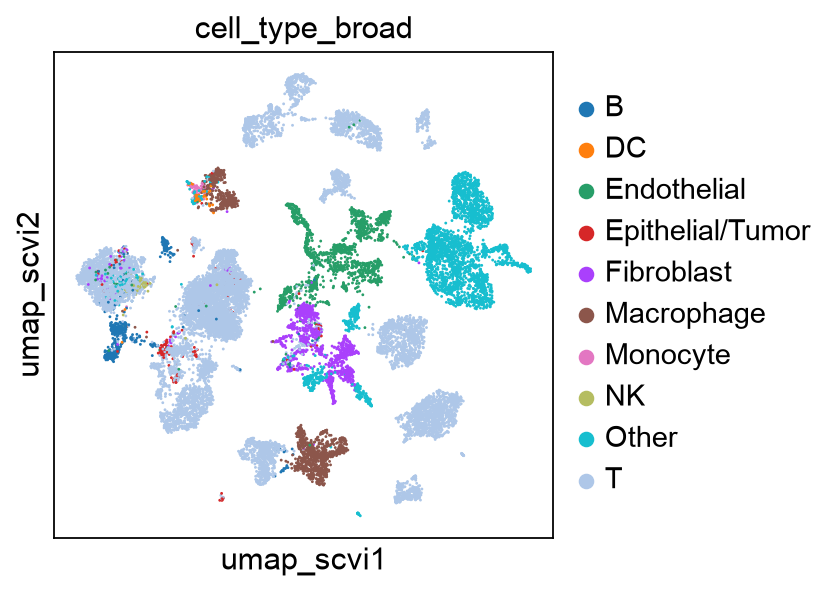

canonical markers found: ['CD3D', 'MS4A1', 'CD14', 'EPCAM', 'PECAM1', 'COL1A1']


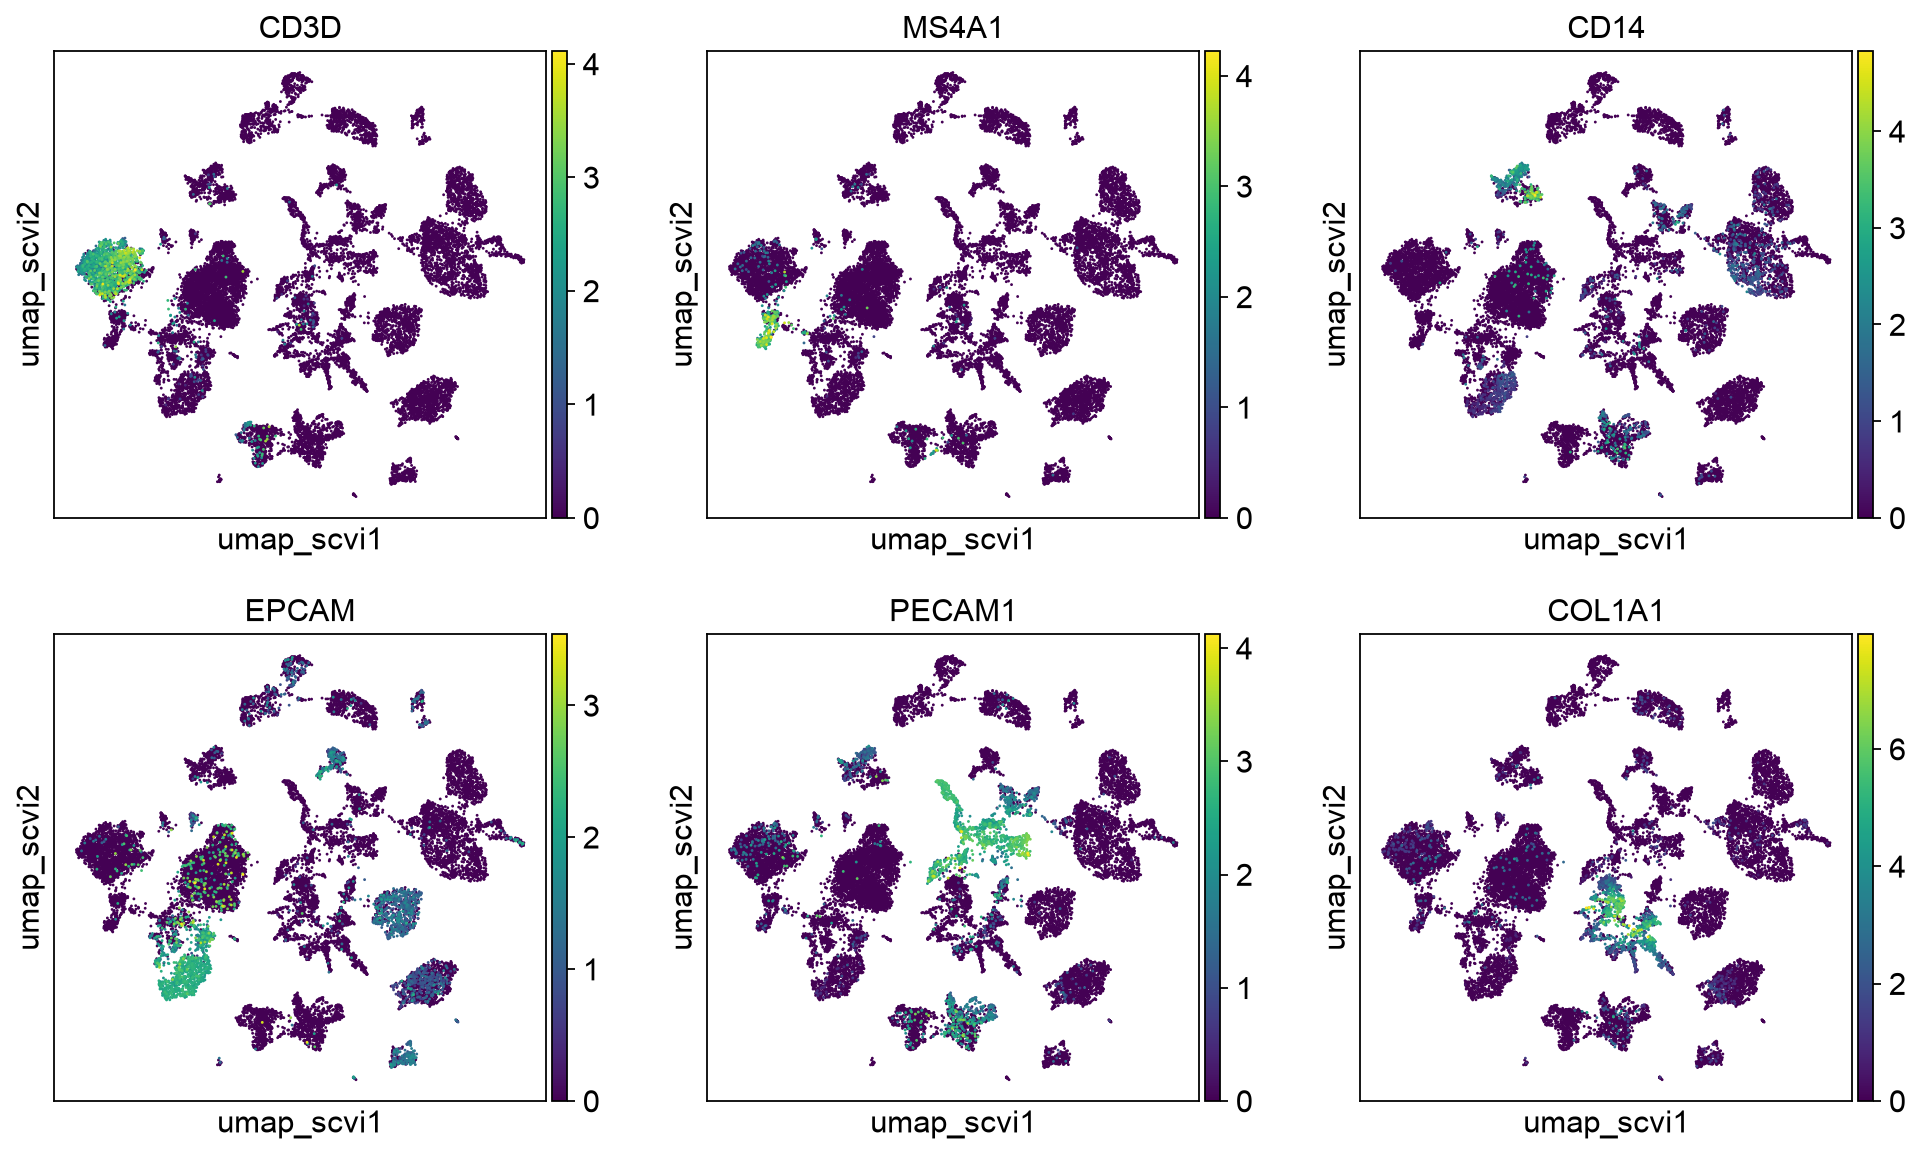


mean log-normalized expression by broad cell type:
                  CD3D  MS4A1  CD14  EPCAM  PECAM1  COL1A1
B                 0.10   1.65  0.01   0.02    0.08    0.13
DC                0.04   0.05  0.21   0.15    0.08    0.08
Endothelial       0.03   0.01  0.11   0.02    2.11    0.09
Epithelial/Tumor  0.22   0.04  0.12   0.33    0.05    0.51
Fibroblast        0.08   0.01  0.05   0.04    0.07    2.69
Macrophage        0.01   0.01  0.69   0.02    0.60    0.11
Monocyte          0.00   0.02  1.57   0.00    0.57    0.00
NK                0.36   0.15  0.00   0.05    0.00    0.04
Other             0.03   0.00  0.17   0.03    0.05    0.13
T                 0.31   0.01  0.04   0.37    0.04    0.07


In [12]:
# TODO: plot the scVI UMAP colored by cell_type_broad, and by canonical markers.
sc.pl.embedding(adata, basis="umap_scvi", color="cell_type_broad")

markers = [g for g in ["CD3D", "MS4A1", "CD14", "EPCAM", "PECAM1", "COL1A1"] if g in adata.raw.var_names]
print("canonical markers found:", markers)
sc.pl.embedding(adata, basis="umap_scvi", color=markers, use_raw=True, ncols=3)

# confirm the labels numerically: mean expression of each marker within each broad type
import scipy.sparse as sp
raw = adata.raw[:, markers].X
raw = raw.toarray() if sp.issparse(raw) else np.asarray(raw)
check = (pd.DataFrame(raw, columns=markers, index=adata.obs_names)
           .groupby(adata.obs["cell_type_broad"].values, observed=True).mean().round(2))
print("\nmean log-normalized expression by broad cell type:")
print(check.to_string())

## 1.8 · Locate your target in the cell types
**TODO:** choose your target gene, plot it, and identify which cell type(s) express it.

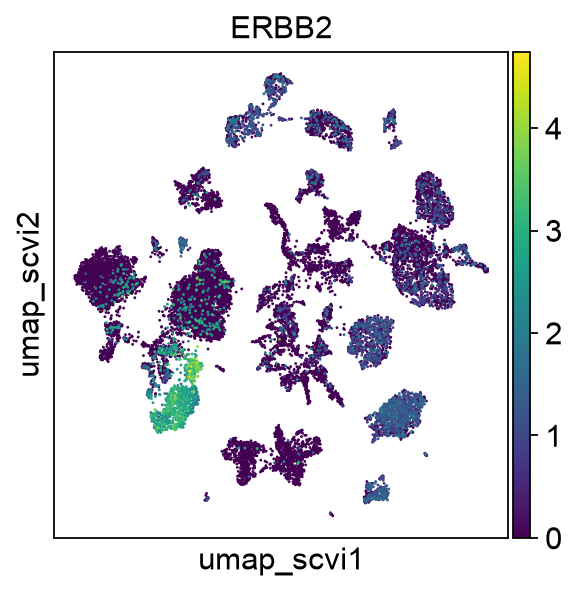


ERBB2 by broad cell type:
                  mean_expr  pct_expressing      n
type                                              
T                      0.52           29.35  10880
NK                     0.26           10.00     50
DC                     0.22           13.89     36
Other                  0.19           17.07   2976
Epithelial/Tumor       0.15           14.47    152
B                      0.13            7.18    529
Fibroblast             0.11            9.61   1072
Macrophage             0.05            3.03   1189
Endothelial            0.04            3.84   1431
Monocyte               0.00            0.00     73


In [13]:
TARGET = "ERBB2"   # HER2: the defining actionable target in breast cancer
# TODO: plot TARGET on the scVI UMAP.
sc.pl.embedding(adata, basis="umap_scvi", color=TARGET, use_raw=True)

# which cell types actually express it?
import scipy.sparse as sp
col = adata.raw[:, TARGET].X
col = np.asarray(col.toarray() if sp.issparse(col) else col).ravel()
tgt = (pd.DataFrame({"expr": col, "type": adata.obs["cell_type_broad"].values})
         .groupby("type", observed=True)["expr"]
         .agg(mean_expr="mean", pct_expressing=lambda s: 100 * (s > 0).mean(), n="size")
         .round(2).sort_values("mean_expr", ascending=False))
print(f"\n{TARGET} by broad cell type:")
print(tgt.to_string())

what the provided broad_type() placed in the 'T' bucket:
cell_type
malignant cell                                                              8526
T cell                                                                      1688
naive T cell                                                                 174
effector memory CD8-positive, alpha-beta T cell                              150
mature NK T cell                                                              72
CD8-positive, alpha-beta regulatory T cell                                    68
CD4-positive, CD25-positive, CCR4-positive, alpha-beta regulatory T cell      67
effector memory CD4-positive, alpha-beta T cell                               67

of 10,880 cells called 'T', 8,526 are actually 'malignant cell'

composition after relabelling:
cell_type_fixed
Malignant           8526
Hepatocyte          2473
T                   2313
Endothelial         1431
Macrophage          1189
Fibroblast          1096
B                    5

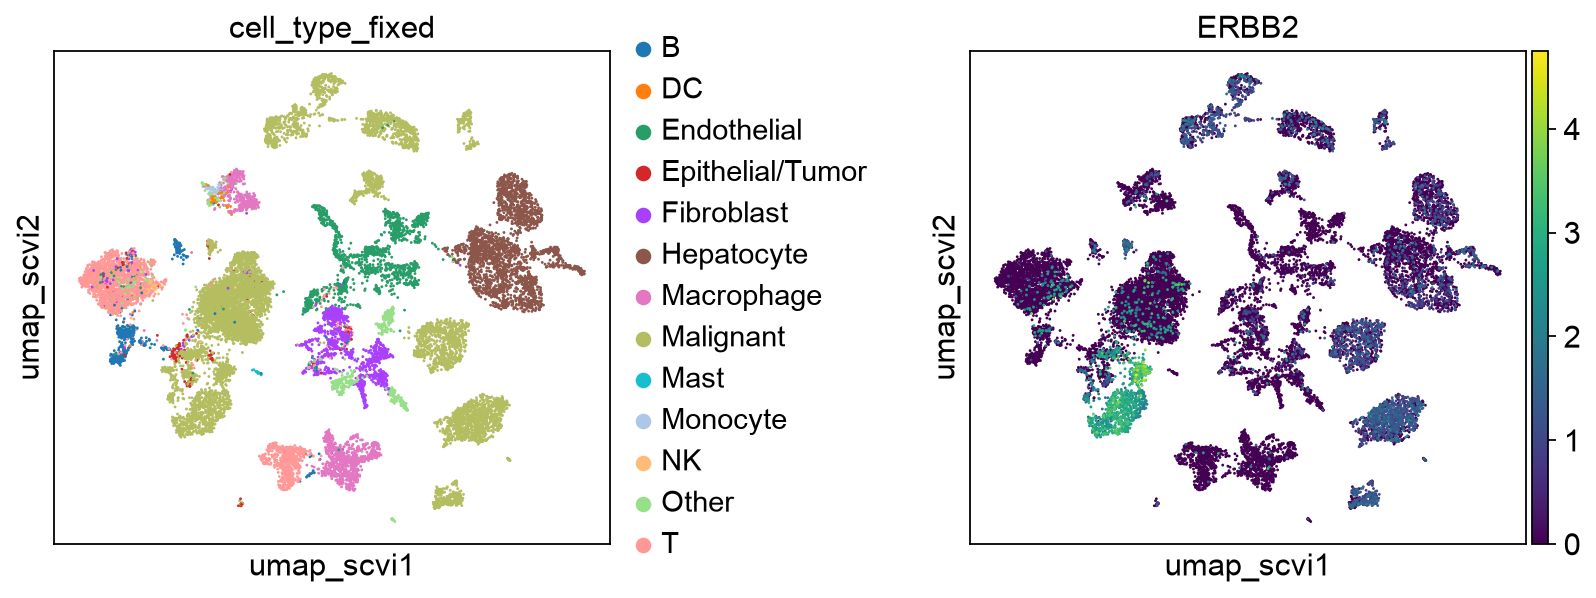

In [14]:
# ---------------------------------------------------------------------------
# EXTRA CELL - my own addition, not part of the provided starter.
# The provided broad_type() tests substrings, and "malignant cell" ends in
# "t cell", so every malignant cell is silently relabeled "T". The same trap
# catches "mast cell" and "myofibroblast cell". That is why ERBB2 appears to be
# highest in "T" in the table above. This cell measures the error and re-derives
# the labels; broad_type() itself is left exactly as provided.
# ---------------------------------------------------------------------------
import scipy.sparse as sp

mis = adata.obs.loc[adata.obs["cell_type_broad"] == "T", "cell_type"].value_counts()
mis = mis[mis > 0]
print("what the provided broad_type() placed in the 'T' bucket:")
print(mis.head(8).to_string())
print(f"\nof {int(mis.sum()):,} cells called 'T', {int(mis.get('malignant cell', 0)):,} "
      f"are actually 'malignant cell'")

def fixed_type(ct):
    c = str(ct).lower()
    if c == "malignant cell": return "Malignant"
    if "mast cell" in c:      return "Mast"
    if "myofibroblast" in c:  return "Fibroblast"
    if "hepatocyte" in c:     return "Hepatocyte"
    return broad_type(ct)

adata.obs["cell_type_fixed"] = adata.obs["cell_type"].map(fixed_type).astype("category")
print("\ncomposition after relabelling:")
print(adata.obs["cell_type_fixed"].value_counts().to_string())

col = adata.raw[:, TARGET].X
col = np.asarray(col.toarray() if sp.issparse(col) else col).ravel()
tgt_fixed = (pd.DataFrame({"expr": col, "type": adata.obs["cell_type_fixed"].values})
               .groupby("type", observed=True)["expr"]
               .agg(mean_expr="mean", pct_expressing=lambda s: 100 * (s > 0).mean(), n="size")
               .round(2).sort_values("mean_expr", ascending=False))
print(f"\n{TARGET} by CORRECTED cell type:")
print(tgt_fixed.to_string())

sc.pl.embedding(adata, basis="umap_scvi", color=["cell_type_fixed", TARGET],
                use_raw=True, wspace=0.5)


**TODO (interpretation):** Which cell type(s) express your target? 

**My answer.** **Malignant (tumor) cells**, but only after correcting a labelling error in the provided code, and the uncorrected answer is badly misleading.

The table from the previous cell says **T cells** express ERBB2 most (mean 0.52, 29.4% of 10,880 cells), with Epithelial/Tumor near the bottom at 0.15. That cannot be right: ERBB2 is HER2, an epithelial receptor tyrosine kinase, and it is not a T-cell gene.

The cause is a substring bug in the provided `broad_type()` helper. It tests `"t cell" in ct`, and the Census label **`"malignant cell"` ends in the characters `"t cell"`**, so every malignant cell is silently relabeled `T`. (`"mast cell"` and `"myofibroblast cell"` are caught the same way.) Of the 10,880 cells called `T`, **8,526, or 78%, are actually `malignant cell`.** I left `broad_type()` exactly as provided and re-derived the labels in a clearly marked extra cell.

With the labels corrected:

| cell type | mean ERBB2 | % expressing | n |
|---|---|---|---|
| **Malignant** | **0.64** | **36.8** | 8,526 |
| Hepatocyte | 0.21 | 18.8 | 2,473 |
| Epithelial/Tumor | 0.15 | 14.5 | 152 |
| **T (genuine)** | **0.06** | **2.5** | 2,313 |
| Macrophage | 0.05 | 3.0 | 1,189 |
| Endothelial | 0.04 | 3.8 | 1,431 |
| Monocyte | 0.00 | 0.0 | 73 |

ERBB2 is **~10.7× higher in malignant cells than in real T cells**, and is essentially absent from the myeloid and endothelial compartments. That tumor-cell-intrinsic pattern is precisely what makes HER2 a usable therapeutic target: the antigen is on the malignant compartment and not on the immune cells surrounding it, so a drug directed at it has a therapeutic window.

One flag for the report: **hepatocytes (n=2,473) carry a modest 0.21.** These donors include liver sites, and low-level HER2 on normal tissue is exactly the on-target/off-tumor exposure that drives toxicity for an antibody-drug conjugate.

---
# PART 2 · Spatial: where those cells sit in the tumor

## 2.1 · Load the provided Visium section  *(provided)*
A real 10x human breast-cancer Visium section. Downloads once on the first run.

In [15]:
spatial = sc.datasets.visium_sge(sample_id="V1_Breast_Cancer_Block_A_Section_1")
spatial.var_names_make_unique()
print(spatial)
print("spots x genes:", spatial.shape)

/var/folders/my/7_8dyc1n26sg4yqmd9z7g8f40000gn/T/ipykernel_3149/520941202.py:1: FutureWarning: Use `squidpy.datasets.visium` instead.
  spatial = sc.datasets.visium_sge(sample_id="V1_Breast_Cancer_Block_A_Section_1")
/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/scanpy/datasets/_datasets.py:555: FutureWarning: Use `squidpy.read.visium` instead.
  return read_visium(sample_dir, source_image_path=source_image_path)


/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


AnnData object with n_obs × n_vars = 3798 × 36601
    obs: 'in_tissue', 'array_row', 'array_col'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'
spots x genes: (3798, 36601)


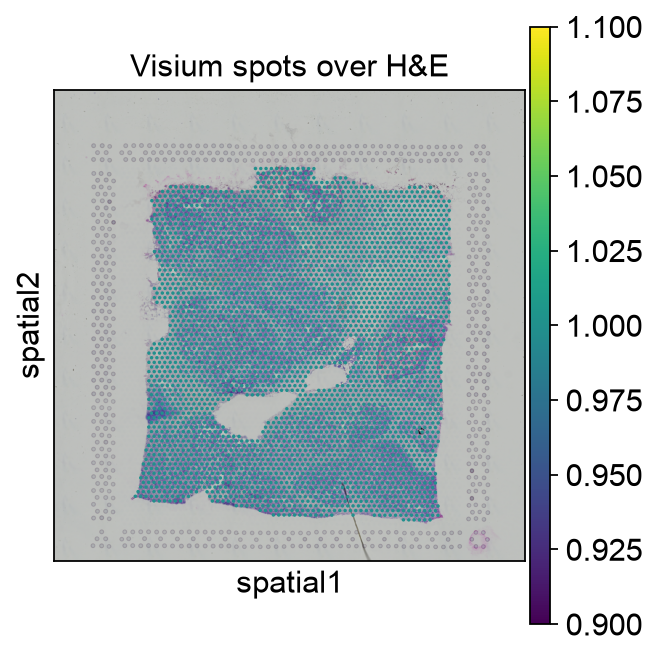

In [16]:
# Assignment Part 2(a) asks to plot the spots over the H&E image on load.
sq.pl.spatial_scatter(spatial, color="in_tissue", title="Visium spots over H&E")


## 2.2 · Pipeline and clustering  *(provided)*

In [17]:
spatial.var["mt"] = spatial.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(spatial, qc_vars=["mt"], inplace=True)
sc.pp.filter_cells(spatial, min_counts=500)
spatial.layers["counts"] = spatial.X.copy()
sc.pp.normalize_total(spatial, target_sum=1e4)
sc.pp.log1p(spatial)
spatial.raw = spatial
sc.pp.highly_variable_genes(spatial, n_top_genes=2000)
sc.pp.pca(spatial)
sc.pp.neighbors(spatial)
sc.tl.leiden(spatial, resolution=0.6, key_added="cluster")
print("spatial domains found:", spatial.obs["cluster"].nunique())

/var/folders/my/7_8dyc1n26sg4yqmd9z7g8f40000gn/T/ipykernel_3149/4117200164.py:11: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(spatial, resolution=0.6, key_added="cluster")


spatial domains found: 9


## 2.3 · Spatial domains on the tissue
**TODO:** draw the clusters back onto the tissue and relate them to tumor, stroma, and immune regions.

cluster
0    732
1    685
2    472
3    409
4    403
5    373
6    361
7    202
8    161



mean log-normalized expression of each marker panel, by spatial domain:
        tumor/epithelial  stroma  immune              call
domain                                                    
0                   2.18    2.16    1.11  tumor/epithelial
1                   1.86    2.61    1.34            stroma
2                   2.26    1.92    0.76  tumor/epithelial
3                   2.16    1.73    0.79  tumor/epithelial
4                   2.33    1.73    0.76  tumor/epithelial
5                   2.61    1.61    0.85  tumor/epithelial
6                   2.12    1.91    0.72  tumor/epithelial
7                   2.11    2.11    0.99  tumor/epithelial
8                   2.50    1.69    0.76  tumor/epithelial


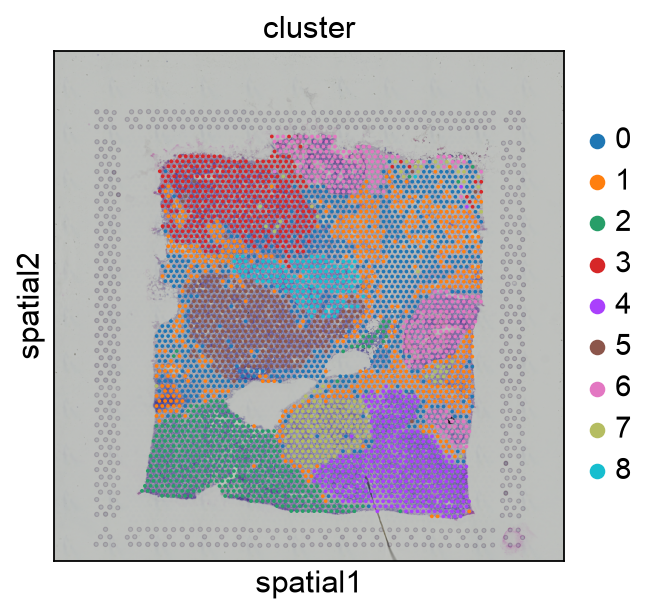

In [18]:
# TODO: plot the clusters on the tissue image.
sq.pl.spatial_scatter(spatial, color="cluster")
print(spatial.obs["cluster"].value_counts().sort_index().to_string())

# Relate each domain to tumor / stroma / immune with canonical marker panels, so
# the domain identities are grounded in expression rather than read off the image.
import scipy.sparse as sp
panels = {
    "tumor/epithelial": ["EPCAM", "KRT8", "KRT18", "ERBB2", "CPB1"],
    "stroma":            ["COL1A1", "COL1A2", "MGP", "DCN", "LUM"],
    "immune":            ["PTPRC", "CD3D", "MS4A1", "CD68", "IGKC"],
}
cols = {}
for name, genes in panels.items():
    gs = [g for g in genes if g in spatial.raw.var_names]
    M = spatial.raw[:, gs].X
    M = M.toarray() if sp.issparse(M) else np.asarray(M)
    cols[name] = np.asarray(M).mean(axis=1)
dom = (pd.DataFrame(cols, index=spatial.obs_names)
         .groupby(spatial.obs["cluster"].values, observed=True).mean().round(2))
dom.index.name = "domain"
dom["call"] = dom.idxmax(axis=1)
print("\nmean log-normalized expression of each marker panel, by spatial domain:")
print(dom.to_string())

**TODO (interpretation):** Do the domains line up with recognizable tissue architecture (tumor nests, stroma, immune areas)?

**My answer.** Partly, and marker evidence is needed to say which domain is which, rather than reading it off the image.

Leiden at resolution 0.6 gives **9 domains** spanning 161-732 spots. Scoring three canonical panels per domain (added to the cell above):

| domain | tumor/epithelial | stroma | immune | reading |
|---|---|---|---|---|
| **1** | 1.86 | **2.61** | **1.34** | stromal / immune compartment |
| **0** | 2.18 | 2.16 | 1.11 | mixed, stroma-leaning |
| 7 | 2.11 | 2.11 | 0.99 | mixed |
| 5 | **2.61** | 1.61 | 0.85 | tumor-rich |
| 8 | 2.50 | 1.69 | 0.76 | tumor-rich |
| 4 | 2.33 | 1.73 | 0.76 | tumor-rich |
| 2 | 2.26 | 1.92 | 0.76 | tumor-rich |

So the domains do line up with recognizable architecture: **domain 1 is the stromal/immune compartment** (highest stroma *and* highest immune, lowest epithelial), **domain 0 sits next to it** as a mixed zone, and **domains 5, 8, 4 and 2 are epithelial-rich tumor territory** with the lowest immune scores.

The independent evidence that these are genuine tissue structures and not clustering artifacts comes from Moran's I in the next section: **MGP** (extracellular matrix), **CPB1** and **CRISP3** (breast secretory epithelium) and five immunoglobulin genes (**IGKC, IGHG1, IGHG3, IGHG4, IGLC2**, plasma cells) are all strongly spatially autocorrelated (I = 0.63-0.87, FDR ≈ 0). Matrix, epithelial and plasma-cell programmes each occupy coherent, contiguous territory.

**Caveat:** the `call` column is crude: 8 of 9 domains take their maximum on the tumor/epithelial panel, because those genes are broadly expressed and a 55 µm Visium spot holds roughly 1-10 cells, so every spot is a mixture. The *relative ranking across domains* is what carries the signal here, not the argmax.

## 2.4 · Spatially variable genes (Moran's I)
The spatial neighbor graph is built for you. **TODO:** compute Moran's I, list the top genes, and plot a few.

In [19]:
sq.gr.spatial_neighbors(spatial)

INFO     Creating graph using `None` transform and `1` libraries.                                                  


/var/folders/my/7_8dyc1n26sg4yqmd9z7g8f40000gn/T/ipykernel_3149/2129188737.py:1: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(spatial)


Top spatially variable genes (Moran's I):
             I  pval_norm_fdr_bh
MGP     0.8685               0.0
MALAT1  0.7625               0.0
CRISP3  0.7263               0.0
CPB1    0.7110               0.0
IGHG3   0.7038               0.0
IGLC2   0.7003               0.0
IGKC    0.6807               0.0
ALB     0.6679               0.0
IGHG1   0.6353               0.0
IGHG4   0.6315               0.0


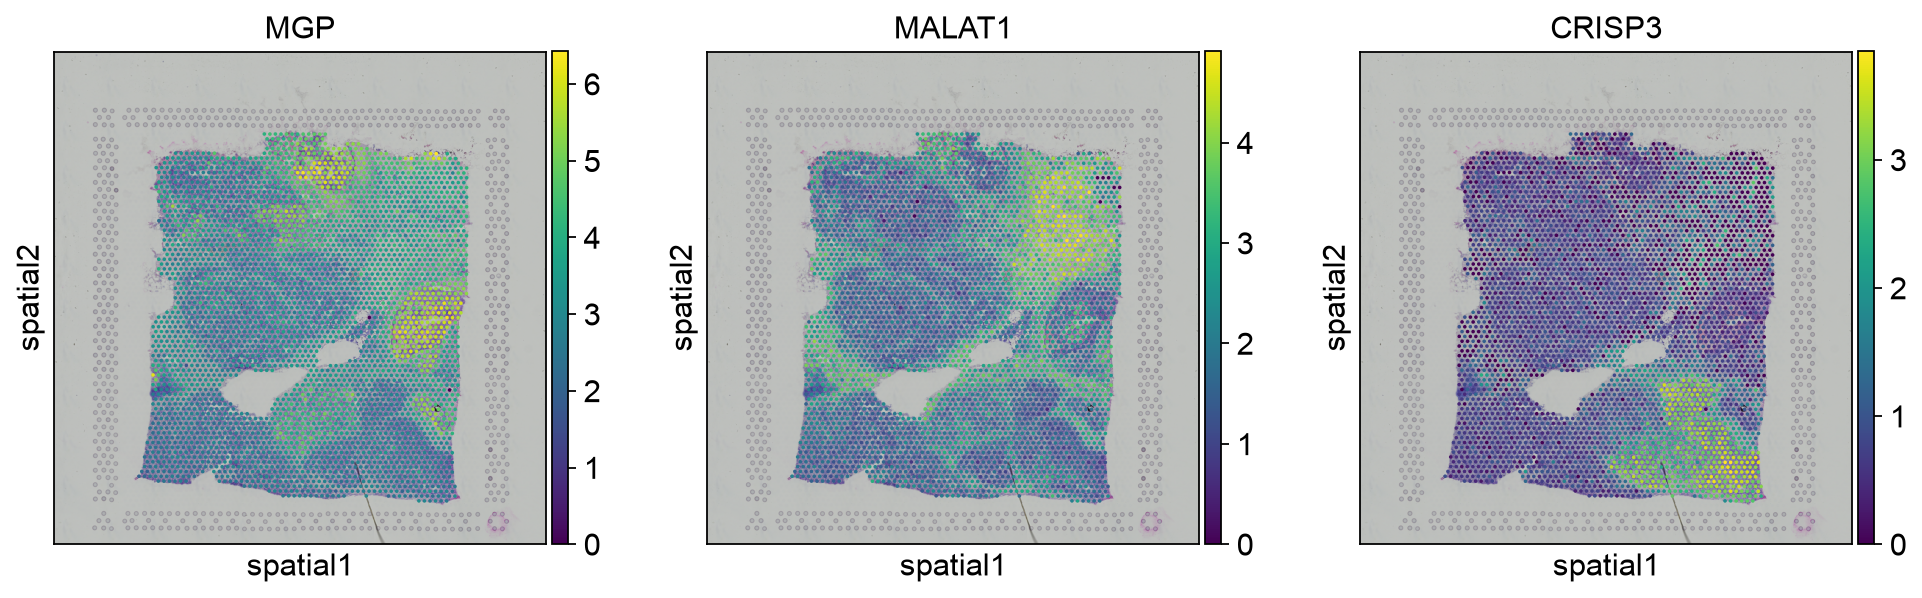

In [20]:
# TODO: compute Moran's I, print the top spatially variable genes, and plot 2-3 on the tissue.
sq.gr.spatial_autocorr(spatial, mode="moran")
top = spatial.uns["moranI"].head(10)
print("Top spatially variable genes (Moran's I):")
print(top[["I", "pval_norm_fdr_bh"]].round(4).to_string())

sq.pl.spatial_scatter(spatial, color=spatial.uns["moranI"].head(3).index.tolist())

## 2.5 · Neighborhood enrichment
**TODO:** compute which domains sit next to each other more than chance, and read off any tumor-immune interface.

  0%|          | 0/1000 [00:00<?, ?/s]

/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


neighborhood enrichment z-scores (positive = adjacent more than chance):
      0     1     2     3     4     5     6     7     8
0  49.8   7.9 -24.0 -16.6 -21.5 -11.6 -15.8  -9.5  -8.1
1   7.9  55.2 -22.2 -18.4 -20.2 -17.2 -18.2  -9.2  -9.7
2 -24.0 -22.2  94.2 -18.8 -17.7 -17.7 -18.2 -13.2 -12.0
3 -16.6 -18.4 -18.8  85.3 -17.3 -15.6 -13.2  -7.4 -10.3
4 -21.5 -20.2 -17.7 -17.3  96.4 -16.0 -16.5  -9.1 -10.8
5 -11.6 -17.2 -17.7 -15.6 -16.0  86.8 -15.2 -11.8  -4.7
6 -15.8 -18.2 -18.2 -13.2 -16.5 -15.2  87.8  -9.2 -10.2
7  -9.5  -9.2 -13.2  -7.4  -9.1 -11.8  -9.2  75.9  -7.4
8  -8.1  -9.7 -12.0 -10.3 -10.8  -4.7 -10.2  -7.4  86.0

most AVOIDING pairs: [('0', '2', np.float64(-24.0)), ('1', '2', np.float64(-22.2)), ('0', '4', np.float64(-21.5))]
most ADJACENT pairs : [('7', '8', np.float64(-7.4)), ('5', '8', np.float64(-4.7)), ('0', '1', np.float64(7.9))]


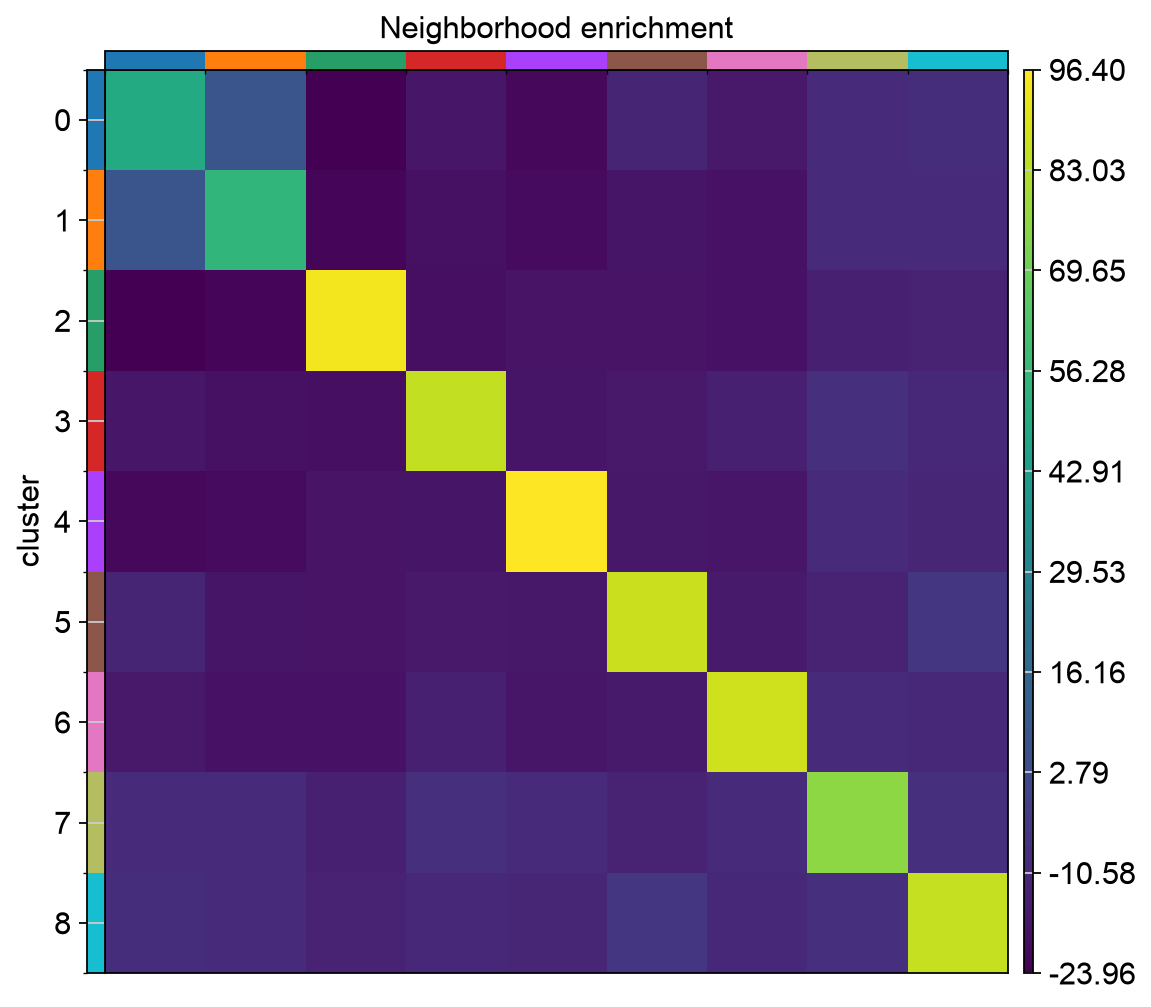

In [21]:
# TODO: run and plot neighborhood enrichment across the clusters.
sq.gr.nhood_enrichment(spatial, cluster_key="cluster")
sq.pl.nhood_enrichment(spatial, cluster_key="cluster")

# print the z-scores so the interfaces can be read off numerically, not just by eye
zs = pd.DataFrame(spatial.uns["cluster_nhood_enrichment"]["zscore"],
                  index=spatial.obs["cluster"].cat.categories,
                  columns=spatial.obs["cluster"].cat.categories)
print("neighborhood enrichment z-scores (positive = adjacent more than chance):")
print(zs.round(1).to_string())
pairs = [(i, j, zs.loc[i, j]) for i in zs.index for j in zs.columns if i < j]
pairs.sort(key=lambda t: t[2])
print("\nmost AVOIDING pairs:", [(a, b, round(z, 1)) for a, b, z in pairs[:3]])
print("most ADJACENT pairs :", [(a, b, round(z, 1)) for a, b, z in pairs[-3:]])

**TODO (interpretation):** Which domains interface more than chance? Is there a tumor-immune boundary?

**My answer.** Strikingly little interfaces more than chance: this section is **strongly compartmentalized**.

Every domain is massively self-enriched (diagonal z = **+75.9 to +96.4**), meaning spots overwhelmingly neighbor their own domain. Of the 36 off-diagonal pairs, **35 are negative**.

There is exactly one exception: **domain 0 and domain 1, z = +7.9**, the only pair adjacent more than chance. From the marker panels above, domain 1 is the stroma/immune-high compartment and domain 0 is the next most stroma-rich. **So the one real interface is a stromal/immune boundary, not a sharp tumor/immune front.**

The strongest avoidances are precisely the tumor-rich domains against that immune/stromal pair:

| pair | z | reading |
|---|---|---|
| 0 - 2 | **-24.0** | mixed zone vs tumor-rich |
| 1 - 2 | **-22.2** | stroma/immune vs tumor-rich |
| 0 - 4 | **-21.5** | mixed zone vs tumor-rich |

**Is there a tumor/immune boundary? Not an infiltrative one.** The immune/stromal compartment and the epithelial-rich cores are spatially segregated: immune cells are banked *alongside* the tumor nests rather than penetrating them. This is the **immune-excluded** phenotype, and it matters clinically, because it is the pattern associated with poor response to therapies that require immune effector cells to reach tumor cells.

## 2.6 · Locate your target in the tissue
**TODO:** color the tissue by the same target gene and describe where it sits.


ERBB2 by spatial domain:
        mean_expr  pct_spots  n_spots
domain                               
5            1.65      99.46      373
4            1.64      99.50      403
8            1.53     100.00      161
7            1.41      96.53      202
3            1.38      97.31      409
2            1.35      99.15      472
6            1.32      96.12      361
0            1.22      80.33      732
1            0.98      83.36      685


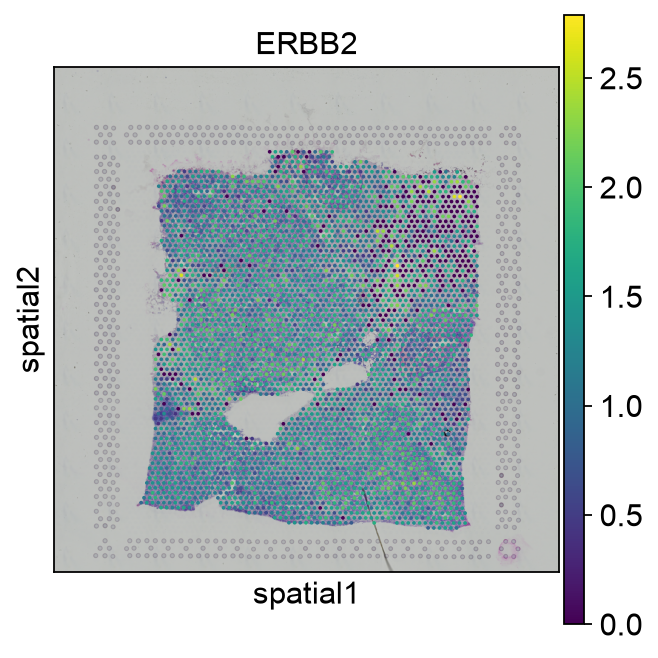

In [22]:
# TODO: plot TARGET on the tissue (if it is present in this section).
if TARGET in spatial.raw.var_names:
    sq.pl.spatial_scatter(spatial, color=TARGET)
    # where does it sit? mean expression of TARGET per spatial domain
    import scipy.sparse as sp
    col = spatial.raw[:, TARGET].X
    col = np.asarray(col.toarray() if sp.issparse(col) else col).ravel()
    per_domain = (pd.DataFrame({"expr": col, "domain": spatial.obs["cluster"].values})
                    .groupby("domain", observed=True)["expr"]
                    .agg(mean_expr="mean", pct_spots=lambda s: 100 * (s > 0).mean(), n_spots="size")
                    .round(2).sort_values("mean_expr", ascending=False))
    print(f"\n{TARGET} by spatial domain:")
    print(per_domain.to_string())
else:
    print(TARGET, "not in this panel; pick a gene present in spatial.raw.var_names")

**TODO (interpretation):** Where does your target sit: tumor core, invasive margin, or an immune niche?

**My answer.** ERBB2 sits in the **tumor core**, not at an immune niche and not confined to an invasive margin.

| domain | mean ERBB2 | % spots | reading (from 2.3) |
|---|---|---|---|
| **5** | **1.65** | 99.5 | most epithelial |
| **4** | **1.64** | 99.5 | tumor-rich |
| 8 | 1.53 | 100.0 | tumor-rich |
| 7 | 1.41 | 96.5 | mixed |
| 3 | 1.38 | 97.3 | tumor-rich |
| 2 | 1.35 | 99.2 | tumor-rich |
| 6 | 1.32 | 96.1 | tumor-rich |
| **0** | **1.22** | 80.3 | mixed, stroma-leaning |
| **1** | **0.98** | 83.4 | stromal / immune |

ERBB2 is detected in nearly every spot (80-100%), but it is clearly **graded**: highest in the most epithelial domains (5, 4, 8) and **lowest in exactly the stromal/immune pair, 1 (0.98) and 0 (1.22)**. The spread is 1.7× top to bottom and the ordering tracks the tumor/epithelial panel score from 2.3, which is the spatial confirmation of the single-cell result, where ERBB2 was ~10.7× higher in malignant cells than in genuine T cells.

Putting this together with the neighborhood enrichment: the ERBB2-high domains are the ones that most strongly *avoid* the immune compartment (5-0 z = -11.6, 4-0 z = -21.5). **The antigen is concentrated exactly where immune cells are least present.**

**Why this matters clinically, and it cuts both ways.** For trastuzumab or a HER2 antibody-drug conjugate this is favorable: the antigen is abundant, tumor-cell-intrinsic and present across the entire section, with no antigen-negative region to seed escape. But the drug must cross the stromal compartment to reach it, and the T cells are parked outside the nests. That geometry argues for a payload-delivering ADC, which only needs to bind and internalise, over a bispecific T-cell engager or a checkpoint strategy, which needs T cells already inside the tumor, and here they are excluded.

**Caveat:** at 55 µm a Visium spot holds roughly 1-10 cells, so every spot is a mixture. The near-universal ERBB2 positivity partly reflects that dilution and does not mean every individual cell is HER2-positive; the between-domain ranking is the trustworthy signal, not the per-spot detection rate.

---
# PART 3 · Connect it (your report)

Write a 4–5 page report (separate PDF) that ties the two views together:

- Which cell types express your target (Part 1), and where those cells sit in the tumor (Part 2).
- Your integration choice, justified with the scores.
- The spatial context and why it matters clinically (a target at the invasive margin versus shut inside the core).
- The limitations of each analysis: donor count and label resolution (single-cell); spot resolution, panel, and segmentation (spatial).

Then **Kernel → Restart & Run All**, commit this notebook and your report to your biot6900 repo, and post the repo link on Canvas.